In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid

In [2]:
#load npz file
mixture_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
mixture_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 11):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_booldhsarr_basis_mixture_fillsize100unique_cycle'+str(i)+'_CT20220301.npz'
    cycle_np_file = np.load(filename)
    mixture_all_cycles.append(cycle_np_file['new_decomp_mixture'])

mixture_all_cycles = np.array(mixture_all_cycles)

1
2
3
4
5
6
7
8
9
10


In [4]:
#load npz file
basis_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
basis_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 11):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_booldhsarr_basis_mixture_fillsize100unique_cycle'+str(i)+'_CT20220301.npz'
    cycle_np_file = np.load(filename)
    basis_all_cycles.append(cycle_np_file['new_decomp_basis'])

basis_all_cycles = np.array(basis_all_cycles)

1
2
3
4
5
6
7
8
9
10


In [3]:
n_components, n_DHSs = mixture_all_cycles[0].shape

In [8]:
mixture_all_cycles.shape

(11, 16, 3591898)

In [25]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

#top 10%
DHS_metadata['ind'] = DHS_metadata.index
DHS_metadata_sortby_mean_signal = DHS_metadata.sort_values(['mean_signal'], ascending=False)
top_10_percent_DHSs = DHS_metadata_sortby_mean_signal.iloc[:int(np.round(n_DHSs/10))]
top_10_percent_DHSs_inds = np.array(top_10_percent_DHSs['ind'])
top_10_percent_DHSs_identifiers = np.array(top_10_percent_DHSs['identifier'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [35]:
#load npz file
added_delta_all_cycles = []
removed_delta_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 11):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100unique_cycle'+str(i)+'_added_removed_CT20220302.npz'
    cycle_np_file = np.load(filename)
    added_delta_all_cycles.append(cycle_np_file['added_delta'])
    removed_delta_all_cycles.append(cycle_np_file['removed_delta'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [36]:
filtered_added_delta_all_cycles = []
filtered_added_flat_inds_all_cycles = []

for i in range(10):
    print(i)
    #when i=0, that is referring to cycle 1 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (original) array value
    if i==0:
        #read in 733 sample x 3.5+ million DHS presence/absence matrix
        dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')
        
    #when i=1, that is referring to cycle 2 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (cycle 1) array value
    else:
        filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_booldhsarr_basis_mixture_fillsize100unique_cycle'+str(i)+'_CT20220301.npz'
        np_file = np.load(filename)
        dhs_arr = np_file['new_dhs_array']
    
    n_biosamples, n_DHSs = dhs_arr.shape
    
    added_flat_inds_single_cycle = []
    delta_vals_single_cycle = []
    
    #when i=1, that is referring to cycle 2 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (cycle 1) array value
    for flat_ind, delta in zip(added_flat_inds_all_cycles[i], added_delta_all_cycles[i]):
        biosample = flat_ind // n_DHSs
        dhs = flat_ind % n_DHSs
        if ~dhs_arr[biosample, dhs]:
            added_flat_inds_single_cycle.append(flat_ind)
            delta_vals_single_cycle.append(delta)
    
    del dhs_arr
    filtered_added_flat_inds_all_cycles.append(np.array(added_flat_inds_single_cycle))
    filtered_added_delta_all_cycles.append(np.array(delta_vals_single_cycle))

0
1
2
3
4
5
6
7
8
9


**Top 10% DHSs for each Mixture**

In [37]:
#quantitatively comparing mixture embeddings
mixture_all_cycles_10per = mixture_all_cycles[:, :, top_10_percent_DHSs_inds]

**Top comp of top 10% mixtures**

In [7]:
mixture_all_cycles_10per_sum = np.sum(mixture_all_cycles_10per, axis=1)

In [8]:
mixture_all_cycles_10per_sum.shape

(11, 359190)

In [9]:
print(359190 * 11)
print(len(np.where(mixture_all_cycles_10per_sum!=0)[0]))

3951090
3951090


In [10]:
for i in mixture_all_cycles_10per_sum:
    print(len(np.where(i==0)[0]))

0
0
0
0
0
0
0
0
0
0
0


In [15]:
# cycle_1_mixture_top_10_percent_not_all_0_inds = np.where(cycle_1_mixture_top_10_percent_sum!=0)[0]

In [38]:
#top comps
mixture_all_cycles_10per_top_comp = np.argmax(mixture_all_cycles_10per, axis=1)
mixture_all_cycles_10per_top_comp_val = np.max(mixture_all_cycles_10per, axis=1)

**Heatmaps (of just DHSs that change component)**

In [39]:
heatmap_mixture_all_cycles_10per_top_comp_comparison = np.zeros((10, 16,16), dtype=int)

changed_dhss_all_cycles = []
changed_dhss_original_comp = []
changed_dhss_new_comp = []
changed_dhss_original_comp_val = []
changed_dhss_new_comp_val = []

for i in range(10):
    changed_dhss_1_cycle = []
    original_comp = []
    new_comp = []
    original_comp_val = []
    new_comp_val = []
    
    for comp1, comp0, dhs, val1, val0 in zip(mixture_all_cycles_10per_top_comp[i+1], 
                                   mixture_all_cycles_10per_top_comp[i], 
                                   range(len(mixture_all_cycles_10per_top_comp[0])),
                                   mixture_all_cycles_10per_top_comp_val[i+1], 
                                   mixture_all_cycles_10per_top_comp_val[i],):
        if comp1!=comp0:
            heatmap_mixture_all_cycles_10per_top_comp_comparison[i, comp1, comp0] += 1
            changed_dhss_1_cycle.append(dhs)
            original_comp.append(comp0)
            new_comp.append(comp1)
            original_comp_val.append(val0)
            new_comp_val.append(val1)
            
    changed_dhss_all_cycles.append(np.array(changed_dhss_1_cycle))
    changed_dhss_original_comp.append(np.array(original_comp))
    changed_dhss_new_comp.append(np.array(new_comp))
    changed_dhss_original_comp_val.append(np.array(original_comp_val))
    changed_dhss_new_comp_val.append(np.array(new_comp_val))

changed_all_dhss_all_cycles = []
for i in changed_dhss_all_cycles:
    changed_all_dhss_all_cycles.append(top_10_percent_DHSs_inds[i])

In [40]:
changed_all_dhss_all_cycles_arr = []
for i in changed_all_dhss_all_cycles:
    changed_all_dhss_all_cycles_arr.extend(i)
changed_all_dhss_all_cycles_arr = np.array(changed_all_dhss_all_cycles_arr)
    
changed_dhss_original_comp_arr = []
for i in changed_dhss_original_comp:
    changed_dhss_original_comp_arr.extend(i)
changed_dhss_original_comp_arr = np.array(changed_dhss_original_comp_arr)
    
changed_dhss_new_comp_arr = []
for i in changed_dhss_new_comp:
    changed_dhss_new_comp_arr.extend(i)
changed_dhss_new_comp_arr = np.array(changed_dhss_new_comp_arr)
    
changed_dhss_original_comp_val_arr = []
for i in changed_dhss_original_comp_val:
    changed_dhss_original_comp_val_arr.extend(i)
changed_dhss_original_comp_val_arr = np.array(changed_dhss_original_comp_val_arr)
    
changed_dhss_new_comp_val_arr = []
for i in changed_dhss_new_comp_val:
    changed_dhss_new_comp_val_arr.extend(i)
changed_dhss_new_comp_val_arr = np.array(changed_dhss_new_comp_val_arr)

In [48]:
inds_for_roiurl = np.argsort(-np.abs(changed_dhss_new_comp_val_arr - changed_dhss_original_comp_val_arr))

In [51]:
dhss_for_roiurl = changed_all_dhss_all_cycles_arr[inds_for_roiurl]

3547692

In [74]:
dhss_for_roiurl_chr = np.array(DHS_metadata.loc[dhss_for_roiurl]['seqname'])
dhss_for_roiurl_start = np.array(DHS_metadata.loc[dhss_for_roiurl]['start'])
dhss_for_roiurl_end = np.array(DHS_metadata.loc[dhss_for_roiurl]['end'])

In [60]:
original_comp_for_roiurl = comps_for_heatmap[changed_dhss_original_comp_arr[inds_for_roiurl]]
new_comp_for_roiurl = comps_for_heatmap[changed_dhss_new_comp_arr[inds_for_roiurl]]

In [68]:
original_comp_for_roiurl[0][:9]

'Stromal B'

In [75]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_delta_100unique_top_changed_mixture_comps_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(str(dhss_for_roiurl_chr[i]) + '\t' + str(dhss_for_roiurl_start[i]) + '\t' + str(dhss_for_roiurl_end[i]) + '\t' + str(original_comp_for_roiurl[i])[:9] + ' -> ' + str(new_comp_for_roiurl[i])[:9] + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_delta_100unique_top_changed_mixture_comps_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_delta_100unique_top_changed_mixture_comps_CT20220303.bed


In [21]:
heatmap_mixture_all_cycles_10per_top_comp_comparison_sum = np.sum(heatmap_mixture_all_cycles_10per_top_comp_comparison, axis=0)

In [24]:
np.sum(heatmap_mixture_all_cycles_10per_top_comp_comparison_sum)

204

Text(0.5, 1.0, 'Comparing Changed DHS Top Components of Previous and New NMF Mixtures Summed Across All Cycles\nDelta Flip, Flip Size=100 Unique Delta Values, Top 10% of DHSs')

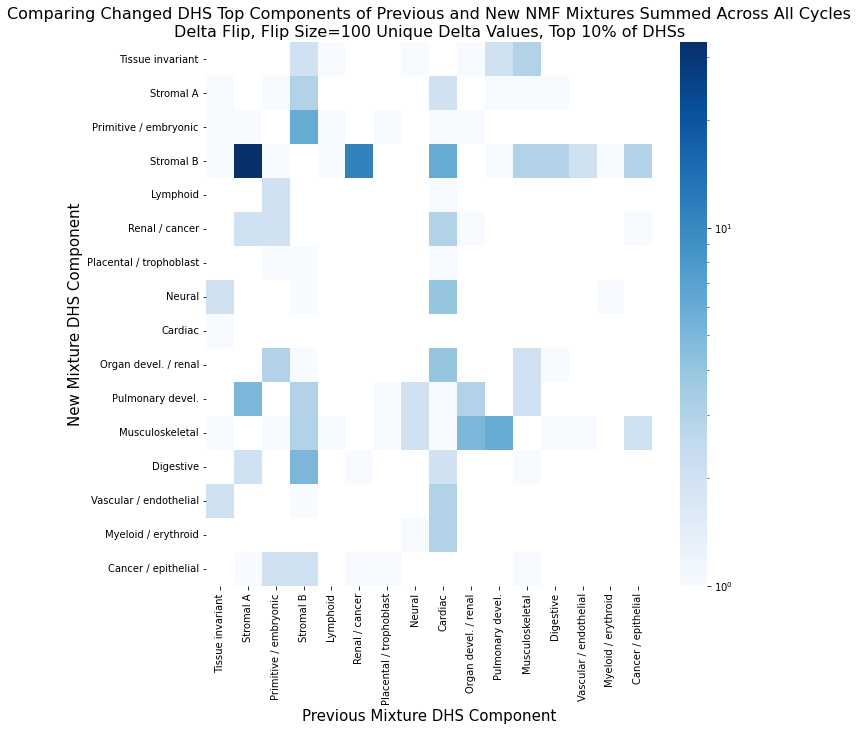

In [26]:
#in plots, yaxis is newest cycle, xaxis is previous cycle
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']

fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')
ax = sns.heatmap(heatmap_mixture_all_cycles_10per_top_comp_comparison_sum, cmap='Blues', cbar=True, xticklabels=comps_for_heatmap, yticklabels=comps_for_heatmap, norm=LogNorm()) # 
ax.set_ylabel('New Mixture DHS Component', fontsize=15)
ax.set_xlabel('Previous Mixture DHS Component', fontsize=15)
ax.set_title('Comparing Changed DHS Top Components of Previous and New NMF Mixtures Summed Across All Cycles\nDelta Flip, Flip Size=100 Unique Delta Values, Top 10% of DHSs', fontsize=16)

**Measuring DHS mixture purity**

In [11]:
#different options for purity:
#1 top value / average
#2 top value / 2nd largest value
#3 top value / sum

In [66]:
example_mixture = np.array([[0.1, 0.6, 0.1, 0.1], [0, 0, 0.15, 0.5], [0, 0, 0.13, 0.13], [0, 0, 0.11, 0.11]])
example_mixture

array([[0.1 , 0.6 , 0.1 , 0.1 ],
       [0.  , 0.  , 0.15, 0.5 ],
       [0.  , 0.  , 0.13, 0.13],
       [0.  , 0.  , 0.11, 0.11]])

In [69]:
example_mixture_mean

array([0.025 , 0.15  , 0.1225, 0.21  ])

In [67]:
example_mixture_top_comp_val = np.max(example_mixture, axis=0)
example_mixture_mean = np.mean(example_mixture, axis=0)
example_mixture_sum = np.sum(example_mixture, axis=0)
example_mixture_second_top_comp_val = np.array([0, 0, 0.13, 0.13])

example_pur_by_mean = example_mixture_top_comp_val / example_mixture_mean
example_pur_by_sum = example_mixture_top_comp_val / example_mixture_sum
example_pur_by_second_top_comp = example_mixture_top_comp_val / example_mixture_second_top_comp_val

/tmp/ipykernel_16803/3452690410.py:8: RuntimeWarning: divide by zero encountered in true_divide
  example_pur_by_second_top_comp = example_mixture_top_comp_val / example_mixture_second_top_comp_val


In [73]:
print(example_pur_by_mean)
print(example_pur_by_mean/4)
print(example_pur_by_sum) # I like by_sum best
print(example_pur_by_second_top_comp)

[4.         4.         1.2244898  2.38095238]
[1.         1.         0.30612245 0.5952381 ]
[1.         1.         0.30612245 0.5952381 ]
[       inf        inf 1.15384615 3.84615385]


In [27]:
#finding value of top comp
mixture_all_cycles_10per_top_comp_val = np.max(mixture_all_cycles_10per, axis=1)

In [26]:
#finding average of all comps
# mixture_all_cycles_10per_mean = np.mean(mixture_all_cycles_10per, axis=1)

In [28]:
#finiding sum of all comps
mixture_all_cycles_10per_sum = np.sum(mixture_all_cycles_10per, axis=1)

In [32]:
#finding second largest value
# mixture_all_cycles_10per_second_top_comp_val = []
# for i in range(11):
#     each_cycle_second_top_comp_val = []
#     for dhs in range(len(mixture_all_cycles_10per[i, 0,:])):
#         second_largest_ind = np.argsort(mixture_all_cycles_10per[i, :, dhs])[-2]
#         each_cycle_second_top_comp_val.append(mixture_all_cycles_10per[i, second_largest_ind, dhs])
#     mixture_all_cycles_10per_second_top_comp_val.append(np.array(each_cycle_second_top_comp_val))
# mixture_all_cycles_10per_second_top_comp_val = np.array(mixture_all_cycles_10per_second_top_comp_val)

In [29]:
# mixture_all_cycles_10per_pur_by_mean = mixture_all_cycles_10per_top_comp_val / mixture_all_cycles_10per_mean
mixture_all_cycles_10per_pur_by_sum = mixture_all_cycles_10per_top_comp_val / mixture_all_cycles_10per_sum
# mixture_all_cycles_10per_pur_by_second_top_comp = mixture_all_cycles_10per_top_comp_val / mixture_all_cycles_10per_second_top_comp_val

In [243]:
pur_diff_10per_tot_between_cycles = []

for i in range(1, 11):
    pur_diff = mixture_all_cycles_10per_pur_by_sum[i, :] - mixture_all_cycles_10per_pur_by_sum[0, :]
    pur_diff_10per_tot_between_cycles.append(pur_diff)
    
pur_diff_10per_tot_between_cycles = np.array(pur_diff_10per_tot_between_cycles)

In [76]:
#all DHSs
mixture_all_cycles_top_comp_val = np.max(mixture_all_cycles, axis=1)
mixture_all_cycles_sum = np.sum(mixture_all_cycles, axis=1)

mixture_all_cycles_pur_by_sum = mixture_all_cycles_top_comp_val / mixture_all_cycles_sum

In [38]:
pur_diff_tot_between_cycles = []

for i in range(1, 11):
    pur_diff = mixture_all_cycles_pur_by_sum[i, :] - mixture_all_cycles_pur_by_sum[0, :]
    pur_diff_tot_between_cycles.append(pur_diff)
    
pur_diff_tot_between_cycles = np.array(pur_diff_tot_between_cycles)

In [40]:
for i in mixture_all_cycles_10per_pur_by_sum:
    print(np.mean(i))

0.5071798
0.5071265
0.50712806
0.5071299
0.5071312
0.5071334
0.50713515
0.5071368
0.5071381
0.5071393
0.507141


In [228]:
# changed_dhss_all_cycles_combined = []
# for i in changed_dhss_all_cycles:
#     changed_dhss_all_cycles_combined.extend(i)
# changed_dhss_all_cycles_combined = np.unique(changed_dhss_all_cycles_combined)

In [45]:
removed_flat_inds_all_cycles[0] % n_DHSs

20563

In [49]:
len(filtered_added_flat_inds_all_cycles)

10

In [50]:
pur_diff_tot_between_cycles.shape

(10, 3591898)

Text(0.5, 1.0, 'Change in Purity of NMF Mixture Loadings Between Each Cycle and Original\nfor DHSs with at Least 1 Added (Previously 0) Call\nDelta Flip, Flip Size=100 Unique Delta Values')

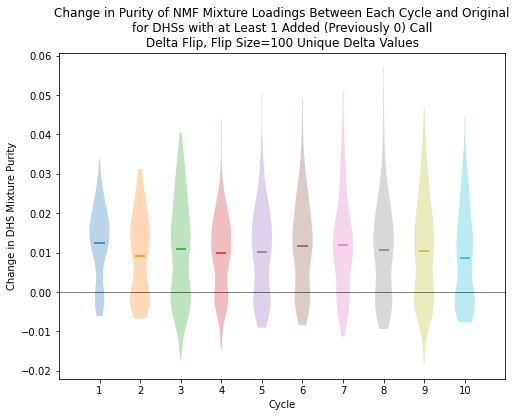

In [63]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

plt.plot([-1, 12], [0, 0], color='k', linewidth=0.5)
for i in range(10):
    plt.violinplot(pur_diff_tot_between_cycles[i, np.unique(filtered_added_flat_inds_all_cycles[i] % n_DHSs)], positions=[i+1], showextrema=False, showmeans=True, points=500)#

# plt.yscale('log')
plt.xlim([0, 11])
# plt.ylim([-0.001, 0.001])
# plt.ylim([-0.005, 0.005])
plt.xticks(np.arange(1, 11))
    
# plt.legend(['Increase in Purity', 'Decrease in Purity', 'No Change in Purity'])

plt.xlabel('Cycle')
plt.ylabel('Change in DHS Mixture Purity')
plt.title('Change in Purity of NMF Mixture Loadings Between Each Cycle and Original\nfor DHSs with at Least 1 Added (Previously 0) Call\nDelta Flip, Flip Size=100 Unique Delta Values')

Text(0.5, 1.0, 'Change in Purity of NMF Mixture Loadings Between Each Cycle and Original\nfor DHSs with at Least 1 Removed Call\nDelta Flip, Flip Size=100 Unique Delta Values')

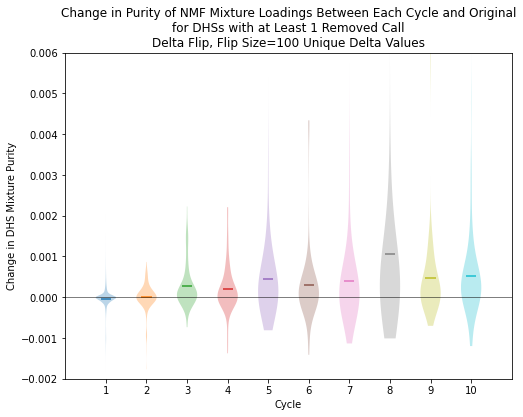

In [67]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

plt.plot([-1, 12], [0, 0], color='k', linewidth=0.5)
for i in range(10):
    plt.violinplot(pur_diff_tot_between_cycles[i, np.unique(removed_flat_inds_all_cycles[i] % n_DHSs)], positions=[i+1], showextrema=False, showmeans=True, points=500)#

# plt.yscale('log')
plt.xlim([0, 11])
plt.ylim([-0.002, 0.006])
# plt.ylim([-0.005, 0.005])
plt.xticks(np.arange(1, 11))
    
# plt.legend(['Increase in Purity', 'Decrease in Purity', 'No Change in Purity'])

plt.xlabel('Cycle')
plt.ylabel('Change in DHS Mixture Purity')
plt.title('Change in Purity of NMF Mixture Loadings Between Each Cycle and Original\nfor DHSs with at Least 1 Removed Call\nDelta Flip, Flip Size=100 Unique Delta Values')

In [84]:
for i in filtered_added_flat_inds_all_cycles:
    print(len(np.unique(i % n_DHSs)))

98
99
100
100
100
99
98
98
98
97


In [85]:
for i in removed_flat_inds_all_cycles:
    print(len(np.unique(i % n_DHSs)))

20563
166
101
100
101
103
100
121
105
101


**Basis purity**

In [68]:
basis_all_cycles_top_comp_val = np.max(basis_all_cycles, axis=2)
basis_all_cycles_sum = np.sum(basis_all_cycles, axis=2)

basis_all_cycles_pur_by_sum = basis_all_cycles_top_comp_val / basis_all_cycles_sum

In [69]:
basis_pur_diff_tot_between_cycles = []

for i in range(1, 11):
    pur_diff = basis_all_cycles_pur_by_sum[i, :] - basis_all_cycles_pur_by_sum[0, :]
    basis_pur_diff_tot_between_cycles.append(pur_diff)
    
basis_pur_diff_tot_between_cycles = np.array(basis_pur_diff_tot_between_cycles)

In [81]:
for i in filtered_added_flat_inds_all_cycles:
    print(len(np.unique(i // n_DHSs)))

17
22
26
24
29
23
27
32
30
34


In [82]:
for i in removed_flat_inds_all_cycles:
    print(len(np.unique(i // n_DHSs)))

647
76
63
56
66
62
49
74
57
68


Text(0.5, 1.0, 'Change in Purity of NMF Basis Loadings Between Each Cycle and Original\nfor Biosamples with at Least 1 Added (Previously 0) Call\nDelta Flip, Flip Size=100 Unique Delta Values')

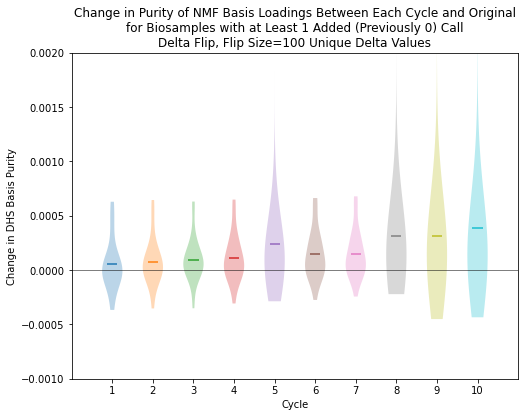

In [87]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

plt.plot([-1, 12], [0, 0], color='k', linewidth=0.5)
for i in range(10):
    plt.violinplot(basis_pur_diff_tot_between_cycles[i, np.unique(filtered_added_flat_inds_all_cycles[i] // n_DHSs)], positions=[i+1], showextrema=False, showmeans=True, points=500)#

# plt.yscale('log')
plt.xlim([0, 11])
plt.ylim([-0.001, 0.002])
# plt.ylim([-0.005, 0.005])
plt.xticks(np.arange(1, 11))
    
# plt.legend(['Increase in Purity', 'Decrease in Purity', 'No Change in Purity'])

plt.xlabel('Cycle')
plt.ylabel('Change in DHS Basis Purity')
plt.title('Change in Purity of NMF Basis Loadings Between Each Cycle and Original\nfor Biosamples with at Least 1 Added (Previously 0) Call\nDelta Flip, Flip Size=100 Unique Delta Values')

Text(0.5, 1.0, 'Change in Purity of NMF Basis Loadings Between Each Cycle and Original\nfor Biosamples with at Least 1 Removed Call\nDelta Flip, Flip Size=100 Unique Delta Values')

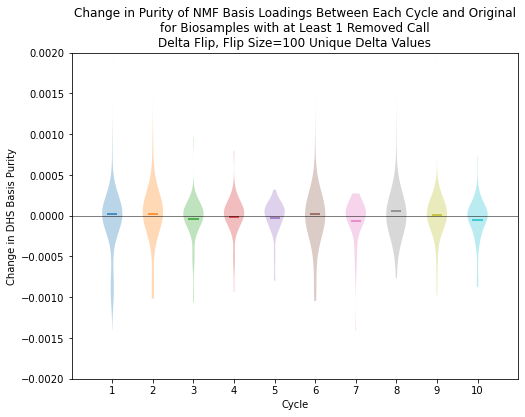

In [86]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

plt.plot([-1, 12], [0, 0], color='k', linewidth=0.5)
for i in range(10):
    plt.violinplot(basis_pur_diff_tot_between_cycles[i, np.unique(removed_flat_inds_all_cycles[i] // n_DHSs)], positions=[i+1], showextrema=False, showmeans=True, points=500)#

# plt.yscale('log')
plt.xlim([0, 11])
plt.ylim([-0.002, 0.002])
# plt.ylim([-0.005, 0.005])
plt.xticks(np.arange(1, 11))
    
# plt.legend(['Increase in Purity', 'Decrease in Purity', 'No Change in Purity'])

plt.xlabel('Cycle')
plt.ylabel('Change in DHS Basis Purity')
plt.title('Change in Purity of NMF Basis Loadings Between Each Cycle and Original\nfor Biosamples with at Least 1 Removed Call\nDelta Flip, Flip Size=100 Unique Delta Values')

**ROIurl**

In [4]:
mixture_top_comp = np.argmax(mixture_all_cycles, axis=1)

In [10]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100unique_cycle1_CT20220301.npz'
cycle_np_file = np.load(filename)
cycle1_diff_flat_array = cycle_np_file['diff_flat_array']
cycle1_sorted_diff_DHS_inds = cycle_np_file['sorted_diff_DHS_inds']
cycle1_sorted_diff_biosample_inds = cycle_np_file['sorted_diff_biosample_inds']

In [64]:
flat_inds_to_1 = cycle_np_file['inds_to_1']
flat_inds_to_0 = cycle_np_file['inds_to_0']

In [65]:
dhs_inds_to_1 = flat_inds_to_1 % n_DHSs
dhs_inds_to_0 = flat_inds_to_0 % n_DHSs

In [26]:
comps_for_heatmap = np.array(['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial'])

In [58]:
changed_comp_dhss_for_roiurl = []
changed_comp_deltas_for_roiurl = []
changed_comp_original_comp_for_roiurl = []
changed_comp_new_comp_for_roiurl = []
top_ind = 0
bottom_ind = 0

while len(changed_comp_dhss_for_roiurl) < 100:
#     print(top_ind, bottom_ind)
    top_delta = cycle1_diff_flat_array[((np.int64(cycle1_sorted_diff_biosample_inds[-(top_ind+1)]) * n_DHSs) + np.int64(cycle1_sorted_diff_DHS_inds[-(top_ind+1)]))]
    bottom_delta = cycle1_diff_flat_array[((np.int64(cycle1_sorted_diff_biosample_inds[bottom_ind]) * n_DHSs) + np.int64(cycle1_sorted_diff_DHS_inds[bottom_ind]))]
    if np.argmax([np.abs(top_delta), np.abs(bottom_delta)])==0:
        delta = top_delta
        dhs_ind = np.int64(cycle1_sorted_diff_DHS_inds[-(top_ind+1)])
        top_ind += 1
    else:
        delta = bottom_delta
        dhs_ind = np.int64(cycle1_sorted_diff_DHS_inds[bottom_ind])
        bottom_ind += 1
    if (mixture_top_comp[0, dhs_ind] != mixture_top_comp[1, dhs_ind]) & (dhs_ind not in changed_comp_dhss_for_roiurl):
        changed_comp_original_comp_for_roiurl.append(comps_for_heatmap[mixture_top_comp[0, dhs_ind]])
        changed_comp_new_comp_for_roiurl.append(comps_for_heatmap[mixture_top_comp[1, dhs_ind]])
        changed_comp_dhss_for_roiurl.append(dhs_ind)
        changed_comp_deltas_for_roiurl.append(delta)

In [60]:
len(changed_comp_dhss_for_roiurl)

100

In [48]:
cycle1_sorted_diff_DHS_inds[-1]

2338142

In [42]:
bottom_ind

153073

In [61]:
changed_comp_dhss_for_roiurl_chr = np.array(DHS_metadata.loc[changed_comp_dhss_for_roiurl]['seqname'])
changed_comp_dhss_for_roiurl_start = np.array(DHS_metadata.loc[changed_comp_dhss_for_roiurl]['start'])
changed_comp_dhss_for_roiurl_end = np.array(DHS_metadata.loc[changed_comp_dhss_for_roiurl]['end'])

In [69]:
c = 0
i_list = []
for i in dhs_inds_to_1:
    if (i in changed_comp_dhss_for_roiurl) and (i not in i_list):
        i_list.append(i)
        c += 1
for i in dhs_inds_to_0:
    if (i in changed_comp_dhss_for_roiurl) and (i not in i_list):
        c += 1
        i_list.append(i)

In [62]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_delta_100unique_top_changed_mixture_comps_by_delta_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(str(changed_comp_dhss_for_roiurl_chr[i]) + '\t' + str(changed_comp_dhss_for_roiurl_start[i]) + '\t' + str(changed_comp_dhss_for_roiurl_end[i]) + '\t' + str(changed_comp_original_comp_for_roiurl[i])[:9] + '->' + str(changed_comp_new_comp_for_roiurl[i])[:9] + ': ' + str(changed_comp_deltas_for_roiurl[i])[:6] + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_delta_100unique_top_changed_mixture_comps_by_delta_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_delta_100unique_top_changed_mixture_comps_by_delta_CT20220303.bed


In [78]:
mixture_all_cycles_pur_by_sum.shape

(11, 3591898)

In [82]:
np.max(mixture_all_cycles_pur_by_sum[0, np.where((mixture_top_comp[0, :] - mixture_top_comp[1, :]) !=0)[0]])

0.50132996

In [81]:
np.mean(mixture_all_cycles_pur_by_sum[0,:])

0.6646667